<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

公司名称：比亚迪股份有限公司；股票代码：002594.SZ
比亚迪是国内新能源汽车龙头企业，主营业务包括新能源乘用车、商用车、动力电池、储能、光伏等业务，是国内新能源产业链代表性上市公司。近数年来受新能源行业政策、市场需求、原材料价格影响，股价波动较大，适合开展行情统计分析。

# 第二部分：研究问题题目及其内涵介绍

研究问题：探究2022–2025年比亚迪（002594.SZ）股票是否存在周一效应，即周一平均涨跌幅与周二至周五是否存在显著差异。
内涵说明：周一效应属于经典的股市日历效应，是金融市场异象之一。该假说认为，受周末信息发布（政策、新闻、海外行情等）、投资者周末决策调整等因素影响，周一的股票平均收益率会和其他交易日存在系统性差别。有效市场假说理论一般认为，在有效市场中，交易日的预期收益率不应存在稳定、可预测的差异。如果数据显示周一平均涨跌幅显著异于其他工作日，则可以视作日历效应存在的证据。
本研究利用Tushare获取比亚迪2022–2025年日线行情，按星期分组，对比各组平均日涨跌幅，检验是否存在该异象。

# 第三部分：数据采集

In [1]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()
df=pro.daily(ts_code="002594.SZ",start_date="20220101",end_date="20251231")
df.head()

,ts_code,trade_date,open,high,low,close,pre_close,change,pct_chg,vol,amount
0,002594.SZ,20251231,99.98,100.20,97.38,97.72,99.75,-2.03,-2.0351,402858.87,3.955310e+06
1,002594.SZ,20251230,99.26,100.15,98.74,99.75,100.21,-0.46,-0.4590,318756.38,3.174698e+06
2,002594.SZ,20251229,100.50,101.30,99.60,100.21,100.01,0.20,0.2000,519166.96,5.209488e+06
3,002594.SZ,20251226,95.28,101.45,95.25,100.01,94.84,5.17,5.4513,1020958.95,1.017856e+07
4,002594.SZ,20251225,94.43,95.23,94.12,94.84,94.42,0.42,0.4448,182201.63,1.725724e+06


# 第四部分：数据分析过程

In [2]:
#数据预处理与分组统计
import pandas as pd
df["trade_date"] = pd.to_datetime(df["trade_date"])
df = df.sort_values("trade_date").reset_index(drop=True)
weekday_map = {0:"周一", 1:"周二", 2:"周三", 3:"周四", 4:"周五"}
df["weekday"] = df["trade_date"].dt.dayofweek.map(weekday_map)
weekday_stats = df.groupby("weekday")["pct_chg"].agg(["count", "mean"]).round(4)
weekday_stats.columns = ["交易日数量", "平均涨跌幅(%)"]
order = ["周一","周二","周三","周四","周五"]
weekday_stats = weekday_stats.reindex(order)
weekday_stats

,交易日数量,平均涨跌幅(%)
weekday,,
周一,190,0.0483
周二,196,0.1002
周三,195,0.0953
周四,196,0.0299
周五,192,-0.0927


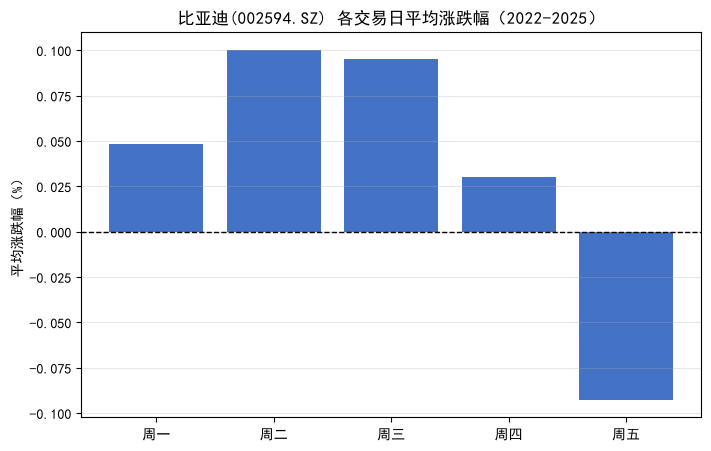

In [ ]:
#绘图
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.figure(figsize=(8,5))
plt.bar(weekday_stats.index, weekday_stats["平均涨跌幅(%)"], color="#4472C4")
plt.axhline(y=0, color="black", linestyle="--", linewidth=1)
plt.ylabel("平均涨跌幅（%）")
plt.title("比亚迪(002594.SZ) 各交易日平均涨跌幅（2022-2025）")
plt.grid(axis="y", alpha=0.3)
plt.show()


# 第五部分：研究结论与经验总结

## 研究结论

在2022–2025年样本区间内，比亚迪（002594.SZ）周一平均涨跌幅0.0483%，周二0.1002%，周三0.0953%，周四0.0299%，周五-0.0927%。周一收益率没有表现出明显偏高或偏低，未发现显著的周一效应，交易日之间的均值差异更可能是随机波动，该结果在一定程度上符合弱式有效市场的预期。

## 经验总结

本次作业通过Tushare获取股票数据，完成数据处理、分组统计与可视化，理解了股市周一效应（日历效应）。同时意识到，仅比较平均涨跌幅不能预测股价，分析结果不能作为投资依据；也体会到在Jupyter中，代码执行顺序会直接影响变量是否可以正常调用。